# iDLG(Arxiv'20): Recovering CelebA-HQ in ResNet-18 (Kaiming-Normal).
📅 **Introduction** : This is the showcase of **iDLG(Arxiv'20)**, relevant to **Fig. 5** in paper. Here are details of the attack scenario:
- Dataset: CelebA-HQ
- Data: Fixed & Random Sampled
- Model: ResNet-18 (**Kaiming-Normal** initialized)
- Data Amount: 1 (Batch Size = 1)
- Attacker Observations: Gradient (Epoch = 1)

🔖 **Reference**
- Paper: *Zhao, Bo, Konda Reddy Mopuri, and Hakan Bilen. "idlg: Improved deep leakage from gradients." arXiv:2001.02610 (2020).*
- Implementations: [github:PatrickZH/Improved-Deep-Leakage-from-Gradients](https://github.com/PatrickZH/Improved-Deep-Leakage-from-Gradients)


⚠️ **Notes**: 
1. **Please install CelebA-HQ dataset if you need to reproduce.** Please refer to `readme.md` for more details.
2. **A different data might be sampled when you try showcase 2 (Random Sampled).** It is decided by hardware you used.
3. **Attack here will just perform** $1$ **time.** But in paper, we have retried $5$ times to report the best result.

## Environment Setup
⭕ **First, Import Dependencies**

See **README.md** for dependency installations.

In [1]:
import logging, sys
import warnings

import torch
from omegaconf import OmegaConf, open_dict

import breaching

# Redirects logs directly into the jupyter notebook
logging.basicConfig(level=logging.INFO, handlers=[logging.StreamHandler(sys.stdout)], format='%(message)s')
logger = logging.getLogger()

# filter warning logs
warnings.filterwarnings("ignore")

⭕ **Second, Loading Configurations**

Loading the configuration of **Use Case** and **Attack**.
- **Use Case** configuration: defined by `case_config`. It describes the use case of attack (i.e. which scenario it attacks on), including:
    - Dataset: CelebA-HQ
    - Data: random sampled
    - Model: ResNet-18 (Kaiming-Normal)
    - Details: Batch Size = 1, Epoch = 1
- **Attack** configuration: defined by `attack_config`. It describes the attack we want to use.

In [2]:
case_config = breaching.get_case_config(case="celeba_hq_identity_random_untrained_kaiming_normal_resnet18")
attack_config = breaching.get_attack_config(attack="iDLG_adam")

# Experiment are preferred to perform on GPU. It will automatically turn to cpu if you have not equipped.
gpu = "cuda:0"
device = torch.device(gpu) if torch.cuda.is_available() else torch.device('cpu')
torch.backends.cudnn.benchmark = case_config.impl.benchmark
setup = dict(device=device, dtype=getattr(torch, case_config.impl.dtype))


Investigating use case celeba_hq_identity_random_untrained_kaiming_normal_resnet18 with server type honest_but_curious.
Loading attack configuration optimization-iDLG_adam.


## Showcase 1: Fixed Sampling
📅 **Introduction**: In this show case, we will fixedly sample a data has been shown in **Fig. 5**.

✅ **Notes**: This showcase is reproducible.

⭕ **1.1 Specified the data we want to sample.**

- Split dataset to `num_classes` of clients. Each clients hold data with same label.
- We take the first client as **victim**, and take its first data as **private data** (i.e. ***target to recover***).

In [3]:
OmegaConf.set_struct(case_config, True)
with open_dict(case_config):
    case_config.data.partition="unique-class"
    case_config.data.default_clients = case_config.data.classes
    case_config.user.user_idx = 0

⭕ **1.2 Compute gradients, and plot the data we has been sampled** **(*target to recover*)**.

Attacker (servers) aims to recover it by observing its gradient. (i.e. `shared_update`)

Computing user update on user 0 in model mode: eval.


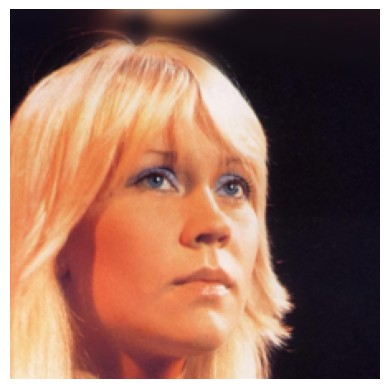

In [4]:
user, server, model, loss_fn = breaching.cases.construct_case(case_config, setup)
server_payload = server.distribute_payload()
shared_update, true_user_data = user.compute_local_updates(server_payload)

user.plot(true_user_data)

⭕ **1.3 Setup Attack.**

In [5]:
# `num_trials` specified the time for retrying.
# We skip retrying for conciseness here, and report result as it finished.
num_trials = 1
OmegaConf.set_struct(attack_config, True)
with open_dict(attack_config):
    attack_config.restarts.num_trials = num_trials

attacker = breaching.attacks.prepare_attack(
    model=server.model, 
    loss=server.loss, 
    cfg_attack=attack_config, 
    setup=setup
)

# You could also run following code for a glance of what you have configured.
# breaching.utils.overview(server, user, attacker)

⭕ **1.4 Recovering it by the configured attack.**

- This attack will be performed by observing its gradients (i.e. `shared_update`).
- The reconstruction is stored by `reconstructed_data`.

In [6]:
reconstructed_data, stats = attacker.reconstruct([server_payload], [shared_update], {})

Recovered labels [0] through strategy yin.
| It: 1 | Rec. loss: 4440460.5000 |  Task loss: 240.9978 | T: 0.87s
| It: 1001 | Rec. loss: 234569.7656 |  Task loss: 160.0814 | T: 106.73s
| It: 2001 | Rec. loss: 159706.2656 |  Task loss: 160.2667 | T: 97.48s
| It: 3001 | Rec. loss: 138880.8750 |  Task loss: 160.8020 | T: 97.73s
| It: 4001 | Rec. loss: 123510.2266 |  Task loss: 161.7498 | T: 97.64s
| It: 5001 | Rec. loss: 101699.3047 |  Task loss: 161.0970 | T: 97.61s
| It: 6001 | Rec. loss: 80466.0000 |  Task loss: 162.0089 | T: 97.72s
| It: 7001 | Rec. loss: 91524.3125 |  Task loss: 161.8130 | T: 97.71s
| It: 8001 | Rec. loss: 81306.9922 |  Task loss: 161.6050 | T: 97.95s
| It: 9001 | Rec. loss: 76828.2500 |  Task loss: 161.0727 | T: 100.34s
| It: 10001 | Rec. loss: 111590.5234 |  Task loss: 168.1008 | T: 100.86s
| It: 11001 | Rec. loss: 84508.8359 |  Task loss: 162.8590 | T: 100.93s
| It: 12001 | Rec. loss: 96121.5234 |  Task loss: 161.8237 | T: 100.94s
| It: 13001 | Rec. loss: 74231.4766

⭕ **1.5 Evaluating the reconstruction qualitatively**

Three metrics will be evaluated for these two images (**reconstruction** and **private data**), including:
- **PSNR** $\uparrow$ : pixel-wise consistency between them.
- **LPIPS** $\downarrow$ : similarity of their latent representations from a same pretrained model.
- **SSIM** $\uparrow$ : similarity scoring of their overall structures, including luminance, contrast, and structure.

In [7]:
metrics = breaching.analysis.report(
    reconstructed_data, 
    true_user_data, 
    [server_payload], 
    server.model, 
    order_batch=True, 
    compute_full_iip=False, 
    cfg_case=case_config, 
    setup=setup
)

Starting evaluations for attack effectiveness report...
METRICS: | MSE: 0.0468 | PSNR: 13.29 | FMSE: 6.3191e-03 | LPIPS: 0.77|
 R-PSNR: 14.12 | IIP-pixel: 100.00% | SSIM: 0.3248 | max R-PSNR: 14.12 | max SSIM: 0.3248 | Label Acc: 100.00%


⭕ **1.6 Evaluating the reconstruction qualitatively**

 Plotting the data we have reconsturcted.

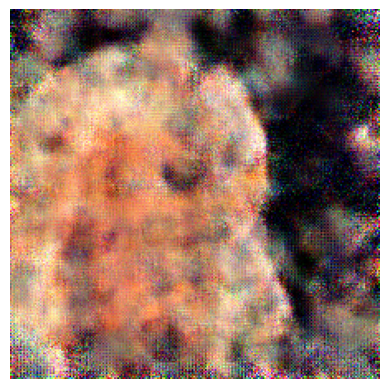

In [8]:
user.plot(reconstructed_data)

## Showcase 2: Random Sampling
📅 **Introduction**: In this show case, we will present the code for random sampling.

⚠️ **Notes**: A different data might be sampled when you reproduce. It is decided by hardware you used.

⭕ **2.1 Specified the seed we want to use.**

Specified the seed to perform randomly sampling.

⚠️ *Notes: A different data might be sampled when you reproduce. It is decided by hardware you used.*

In [9]:
# @ Notes: These are the seeds we have been generated and evaluated with
# @ Implementations: `seeds = torch.randint(0, 10000000, (20, ))`
#   seeds = [ 
#       6400942, 7261425, 982363,  8534671, 6679360, 
#       9001950, 2737937, 6241508, 8351731, 3572673, 
#       7101754, 6498150, 8152325, 5679244, 226193, 
#       1513304, 6483568, 9155478, 796668,  7593953
#   ]

case_config = breaching.get_case_config(case="celeba_hq_identity_random_untrained_kaiming_normal_resnet18")
seed = 9001950
OmegaConf.set_struct(case_config, True)
with open_dict(case_config):
    case_config.data.partition_seed = seed
breaching.utils.set_random_seed(seed)

Investigating use case celeba_hq_identity_random_untrained_kaiming_normal_resnet18 with server type honest_but_curious.


⭕ **2.2 Compute gradients, and plot the data we has been sampled** **(*target to recover*)**.

- This data is the **private data** held by the victim (i.e. the client). 
- Attacker (servers) aims to recover it by observing its gradient. (i.e. `shared_update`)

Computing user update on user 0 in model mode: eval.


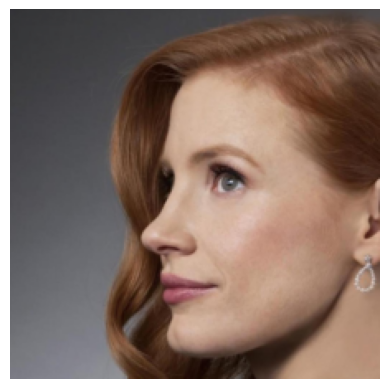

In [10]:
user, server, model, loss_fn = breaching.cases.construct_case(case_config, setup)
server_payload = server.distribute_payload()
shared_update, true_user_data = user.compute_local_updates(server_payload)

user.plot(true_user_data)


⭕ **2.3 Setup Attack.**

In [11]:
# `num_trials` specified the time for retrying.
# We skip retrying for conciseness here, and report result as it finished.
num_trials = 1
OmegaConf.set_struct(attack_config, True)
with open_dict(attack_config):
    attack_config.restarts.num_trials = num_trials

attacker = breaching.attacks.prepare_attack(
    model=server.model, 
    loss=server.loss, 
    cfg_attack=attack_config, 
    setup=setup
)

# You could also run following code for a glance of what you have configured.
# breaching.utils.overview(server, user, attacker)

⭕ **2.4 Recovering it by the configured attack.**

- This attack will be performed by observing its gradients (i.e. `shared_update`).
- The reconstruction is stored by `reconstructed_data`.

In [12]:
reconstructed_data, stats = attacker.reconstruct([server_payload], [shared_update], {})

Recovered labels [100] through strategy yin.
| It: 1 | Rec. loss: 3504475.2500 |  Task loss: 58.9679 | T: 0.08s
| It: 1001 | Rec. loss: 36177.2852 |  Task loss: 24.4853 | T: 97.31s
| It: 2001 | Rec. loss: 27261.4824 |  Task loss: 24.0136 | T: 97.12s
| It: 3001 | Rec. loss: 17733.4395 |  Task loss: 24.6365 | T: 97.09s
| It: 4001 | Rec. loss: 16291.7539 |  Task loss: 24.6699 | T: 97.08s
| It: 5001 | Rec. loss: 15651.3154 |  Task loss: 24.6673 | T: 96.97s
| It: 6001 | Rec. loss: 16263.2539 |  Task loss: 24.0518 | T: 97.19s
| It: 7001 | Rec. loss: 17152.9453 |  Task loss: 24.4049 | T: 97.17s
| It: 8001 | Rec. loss: 27991.7988 |  Task loss: 24.1176 | T: 97.04s
| It: 9001 | Rec. loss: 18946.9473 |  Task loss: 24.5104 | T: 97.93s
| It: 10001 | Rec. loss: 62470.2266 |  Task loss: 23.6764 | T: 99.34s
| It: 11001 | Rec. loss: 36486.5547 |  Task loss: 23.6677 | T: 99.43s
| It: 12001 | Rec. loss: 26669.3594 |  Task loss: 24.3242 | T: 99.54s
| It: 13001 | Rec. loss: 20869.9902 |  Task loss: 24.7368

⭕ **2.5 Evaluating the reconstruction qualitatively**

Three metrics will be evaluated for these two images (***reconstruction*** and ***private data***), including:
- ***PSNR*** $\uparrow$ : pixel-wise consistency between them.
- ***LPIPS*** $\downarrow$ : similarity of their latent representations from a same pretrained model.
- ***SSIM*** $\uparrow$ : similarity scoring of their overall structures, including luminance, contrast, and structure.

In [13]:
metrics = breaching.analysis.report(
    reconstructed_data, 
    true_user_data, 
    [server_payload], 
    server.model, 
    order_batch=True, 
    compute_full_iip=False, 
    cfg_case=case_config, 
    setup=setup
)

Starting evaluations for attack effectiveness report...
METRICS: | MSE: 0.0224 | PSNR: 16.50 | FMSE: 5.2247e-04 | LPIPS: 0.81|
 R-PSNR: 17.63 | IIP-pixel: 100.00% | SSIM: 0.3007 | max R-PSNR: 17.63 | max SSIM: 0.3007 | Label Acc: 100.00%


⭕ **2.6 Evaluating the reconstruction qualitatively**

 Plotting the data we have reconsturcted.

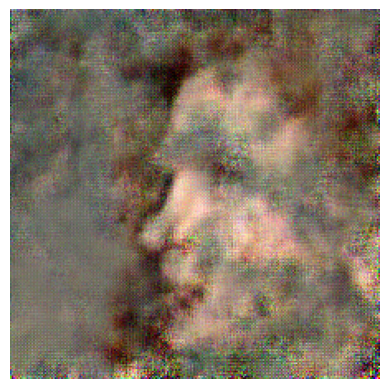

In [14]:
user.plot(reconstructed_data)